In [1]:
from pathlib import Path
import polars as pl

# Since your notebook is inside 'notebooks/', step up one level to the root directory
DATA_DIR = Path("../home-credit-default-risk")
train_path = DATA_DIR / "application_train.csv"

# 1. Scan the CSV lazily
df_train = pl.scan_csv(train_path)

# --- 1. Target Balance Inspection ---
print("--- TARGET BALANCE ---")
target_counts = df_train.select(
    pl.col("TARGET").value_counts(normalize=True) * 100
).collect()
print(target_counts)

# --- 2. Data Structure & Types ---
print("\n--- DATA SHAPE & TYPES ---")
schema = df_train.collect_schema()
print(f"Total Features: {len(schema)}")

# --- 3. Missing Values Summary ---
missing_df = (
    df_train.select(pl.all().is_null().sum())
    .collect()
    .transpose(include_header=True, header_name="column", column_names=["Missing Count"])
)
missing_df = missing_df.with_columns(
    (pl.col("Missing Count") * 100 / df_train.select(pl.len()).collect().item()).alias("Missing %")
)
top_missing = missing_df.filter(pl.col("Missing Count") > 0).sort("Missing %", descending=True).head(10)
print("\n--- TOP 10 COLUMNS WITH HIGHEST MISSING VALUES ---")
print(top_missing)

# --- 4. Sample Data Inspection (First 5 and Last 5 rows of Train) ---
print("\n--- APPLICATION TRAIN SAMPLE (Head & Tail) ---")
train_sample = pl.concat([
    df_train.select(["SK_ID_CURR", "TARGET"]).head(5).collect(),
    df_train.select(["SK_ID_CURR", "TARGET"]).tail(5).collect()
])
print(train_sample)

--- TARGET BALANCE ---
shape: (2, 1)
┌────────────────┐
│ TARGET         │
│ ---            │
│ struct[2]      │
╞════════════════╡
│ {100,8.072882} │
│ {0,91.927118}  │
└────────────────┘

--- DATA SHAPE & TYPES ---
Total Features: 122

--- TOP 10 COLUMNS WITH HIGHEST MISSING VALUES ---
shape: (10, 3)
┌──────────────────────────┬───────────────┬───────────┐
│ column                   ┆ Missing Count ┆ Missing % │
│ ---                      ┆ ---           ┆ ---       │
│ str                      ┆ u32           ┆ f64       │
╞══════════════════════════╪═══════════════╪═══════════╡
│ COMMONAREA_AVG           ┆ 214865        ┆ 69.872297 │
│ COMMONAREA_MODE          ┆ 214865        ┆ 69.872297 │
│ COMMONAREA_MEDI          ┆ 214865        ┆ 69.872297 │
│ NONLIVINGAPARTMENTS_AVG  ┆ 213514        ┆ 69.432963 │
│ NONLIVINGAPARTMENTS_MODE ┆ 213514        ┆ 69.432963 │
│ NONLIVINGAPARTMENTS_MEDI ┆ 213514        ┆ 69.432963 │
│ FONDKAPREMONT_MODE       ┆ 210295        ┆ 68.386172 │
│ LIVINGAPAR


APPLICATION TRAIN: MISSINGNESS AND DEFAULT RATE ANALYSIS
Showing 11 features with at least 1% missing data


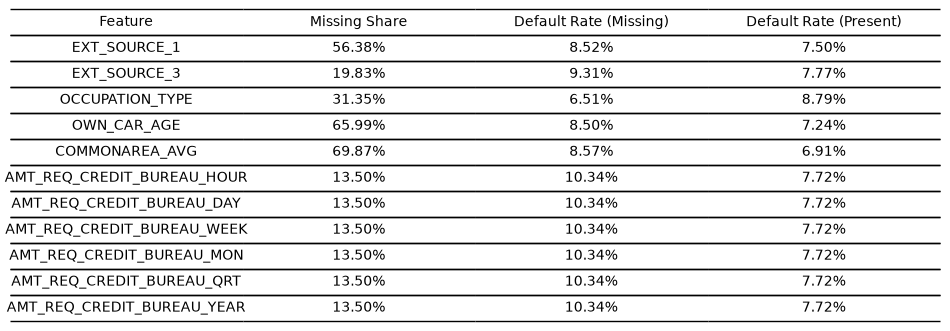


BUREAU: MISSING DATA ANALYSIS
Showing 1 bureau features with at least 1% missing data


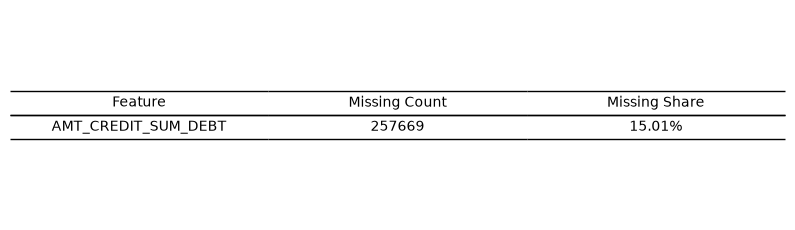

In [4]:

from pathlib import Path
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

# Dataset directory
DATA_DIR = Path("../home-credit-default-risk")

# =====================================================
# 1. APPLICATION TRAIN - MISSINGNESS AND DEFAULT RATES
# =====================================================

print("\nAPPLICATION TRAIN: MISSINGNESS AND DEFAULT RATE ANALYSIS")

train_path = DATA_DIR / "application_train.csv"
df = pl.scan_csv(train_path)

# Features to investigate
check = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "OCCUPATION_TYPE",
    "ORGANIZATION_TYPE",
    "NAME_CONTRACT_TYPE",
    "OWN_CAR_AGE",
    "COMMONAREA_AVG",
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_DAY",
    "AMT_REQ_CREDIT_BUREAU_WEEK",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR",
    "DEF_30_CNT_SOCIAL_CIRCLE",
    "DEF_60_CNT_SOCIAL_CIRCLE",
    "DAYS_LAST_PHONE_CHANGE",
    "REGION_RATING_CLIENT",
    "REGION_RATING_CLIENT_W_CITY"
]

results = []

for feature in check:
    stats = df.select([
        pl.col(feature).is_null().mean().alias("Missing Share"),

        pl.col("TARGET")
        .filter(pl.col(feature).is_null())
        .mean()
        .alias("Default Rate (Missing)"),

        pl.col("TARGET")
        .filter(pl.col(feature).is_not_null())
        .mean()
        .alias("Default Rate (Present)")
    ]).collect()

    results.append({
        "Feature": feature,
        "Missing Share": stats["Missing Share"].item(),
        "Default Rate (Missing)": stats["Default Rate (Missing)"].item(),
        "Default Rate (Present)": stats["Default Rate (Present)"].item()
    })

df_results = pl.DataFrame(results)

# Exclude immaterial missingness below 1%
df_results = df_results.filter(
    pl.col("Missing Share") >= 0.01
)

df_plot = df_results.to_pandas()

for c in df_plot.columns[1:]:
    df_plot[c] = df_plot[c].map(
        lambda x: f"{x:.2%}" if pd.notna(x) else "N/A"
    )

# Display application table
print(f"Showing {len(df_plot)} features with at least 1% missing data")

fig, ax = plt.subplots(
    figsize=(12, max(4, len(df_plot) * 0.35))
)
ax.axis("off")

table = ax.table(
    cellText=df_plot.values.tolist(),
    colLabels=[
        "Feature",
        "Missing Share",
        "Default Rate (Missing)",
        "Default Rate (Present)"
    ],
    loc="center",
    cellLoc="center",
    edges="horizontal"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)

plt.subplots_adjust(top=0.85, bottom=0.10)
plt.show()


# =====================================================
# 2. BUREAU - MISSING DATA ANALYSIS
# =====================================================

print("\nBUREAU: MISSING DATA ANALYSIS")

bureau_path = DATA_DIR / "bureau.csv"
df_bureau = pl.scan_csv(bureau_path)

# Bureau features to investigate
bureau_check = [
    "CREDIT_DAY_OVERDUE",
    "AMT_CREDIT_SUM_OVERDUE",
    "AMT_CREDIT_SUM_DEBT",
    "CREDIT_ACTIVE",
    "CNT_CREDIT_PROLONG"
]

bureau_results = []

for feature in bureau_check:
    stats = df_bureau.select([
        pl.col(feature).is_null().sum().alias("Missing Count"),
        pl.col(feature).is_null().mean().alias("Missing Share")
    ]).collect()

    bureau_results.append({
        "Feature": feature,
        "Missing Count": stats["Missing Count"].item(),
        "Missing Share": stats["Missing Share"].item()
    })

df_bureau_results = pl.DataFrame(bureau_results)

# Exclude immaterial missingness below 1%
df_bureau_results = df_bureau_results.filter(
    pl.col("Missing Share") >= 0.01
)

df_bureau_plot = df_bureau_results.to_pandas()

# Format percentages
df_bureau_plot["Missing Share"] = df_bureau_plot[
    "Missing Share"
].map(lambda x: f"{x:.2%}")

# Display bureau table
print(
    f"Showing {len(df_bureau_plot)} bureau features "
    "with at least 1% missing data"
)

fig, ax = plt.subplots(
    figsize=(10, max(3, len(df_bureau_plot) * 0.5))
)
ax.axis("off")

table = ax.table(
    cellText=df_bureau_plot.values.tolist(),
    colLabels=[
        "Feature",
        "Missing Count",
        "Missing Share"
    ],
    loc="center",
    cellLoc="center",
    edges="horizontal"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)

plt.subplots_adjust(top=0.85, bottom=0.15)
plt.show()


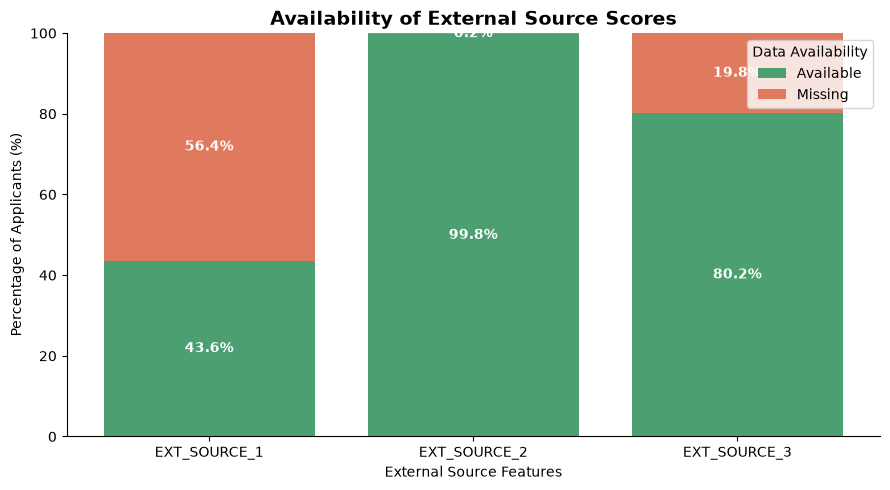

Spearman correlation with TARGET:
EXT_SOURCE_3   -0.166330
EXT_SOURCE_1   -0.151128
EXT_SOURCE_2   -0.147332
Name: TARGET, dtype: float64


In [12]:
from pathlib import Path
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt

# Since your notebook is inside 'notebooks/', step up one level to the root directory
DATA_DIR = Path("../home-credit-default-risk")
train_path = DATA_DIR / "application_train.csv"

# Load the dataset
df = pl.read_csv(train_path)


# Convert to Pandas
df = df.to_pandas()

# External source features
ext_cols = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

# Calculate available and missing percentages
available = df[ext_cols].notna().mean() * 100
missing = df[ext_cols].isna().mean() * 100

# Create the stacked bar chart
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    ext_cols,
    available,
    label="Available",
    color="#4C9F70"
)

ax.bar(
    ext_cols,
    missing,
    bottom=available,
    label="Missing",
    color="#E07A5F"
)

# Add percentage labels
for i, col in enumerate(ext_cols):
    ax.text(
        i,
        available[col] / 2,
        f"{available[col]:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontweight="bold"
    )

    ax.text(
        i,
        available[col] + missing[col] / 2,
        f"{missing[col]:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontweight="bold"
    )

# Formatting
ax.set_title(
    "Availability of External Source Scores",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Percentage of Applicants (%)")
ax.set_xlabel("External Source Features")

ax.set_ylim(0, 100)
ax.legend(title="Data Availability", loc="upper right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

ext_cols = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

# Calculate Spearman correlation using available observations
correlations = df[ext_cols + ["TARGET"]].corr(
    method="spearman"
)["TARGET"].drop("TARGET")

print("Spearman correlation with TARGET:")
print(correlations.sort_values())


In [13]:
from scipy.stats import spearmanr

for col in ext_cols:
    corr, p_value = spearmanr(
        df[col],
        df["TARGET"],
        nan_policy="omit"
    )

    print(f"\n{col}")
    print(f"Spearman correlation: {corr:.4f}")
    print(f"P-value: {p_value:.6g}")


EXT_SOURCE_1
Spearman correlation: -0.1511
P-value: 0

EXT_SOURCE_2
Spearman correlation: -0.1473
P-value: 0

EXT_SOURCE_3
Spearman correlation: -0.1663
P-value: 0


In [7]:
from pathlib import Path
import polars as pl
import pandas as pd

# Define data directory
DATA_DIR = Path("../home-credit-default-risk")
train_path = DATA_DIR / "application_train.csv"

# Load dataset
df = pl.read_csv(train_path)

# Convert to Pandas
df = df.to_pandas()

# External credit score columns
ext_cols = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

# Calculate descriptive statistics and default rates by decile
for col in ext_cols:
    print(f"\n{'='*60}")
    print(f"ANALYSIS: {col}")
    print(f"{'='*60}")

    # Descriptive statistics
    print("\nDescriptive Statistics:")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Unique values:", df[col].nunique())
    print("Missing values:", df[col].isna().sum())

    # Group scores into deciles
    score_group = pd.qcut(
        df[col],
        q=10,
        duplicates="drop"
    )

    # Calculate default rate by group
    results = (
        df.groupby(score_group, observed=True)
        .agg(
            applicants=("TARGET", "count"),
            defaults=("TARGET", "sum"),
            default_rate=("TARGET", "mean"),
            avg_score=(col, "mean")
        )
    )

    print("\nDefault Rate by Score Group:")
    print(results.to_string())


ANALYSIS: EXT_SOURCE_1

Descriptive Statistics:
Minimum: 0.014568132412445587
Maximum: 0.9626927705613059
Mean: 0.5021298056566624
Median: 0.5059979305057544
Unique values: 114584
Missing values: 173378

Default Rate by Score Group:
                               applicants  defaults  default_rate  avg_score
EXT_SOURCE_1                                                                
(0.013600000000000001, 0.213]       13414      2356      0.175637   0.149906
(0.213, 0.296]                      13413      1555      0.115932   0.255799
(0.296, 0.369]                      13414      1220      0.090950   0.333389
(0.369, 0.438]                      13412      1124      0.083806   0.403800
(0.438, 0.506]                      13415       898      0.066940   0.472106
(0.506, 0.573]                      13412       808      0.060245   0.539670
(0.573, 0.64]                       13413       689      0.051368   0.606593
(0.64, 0.71]                        13413       588      0.043838   0.675

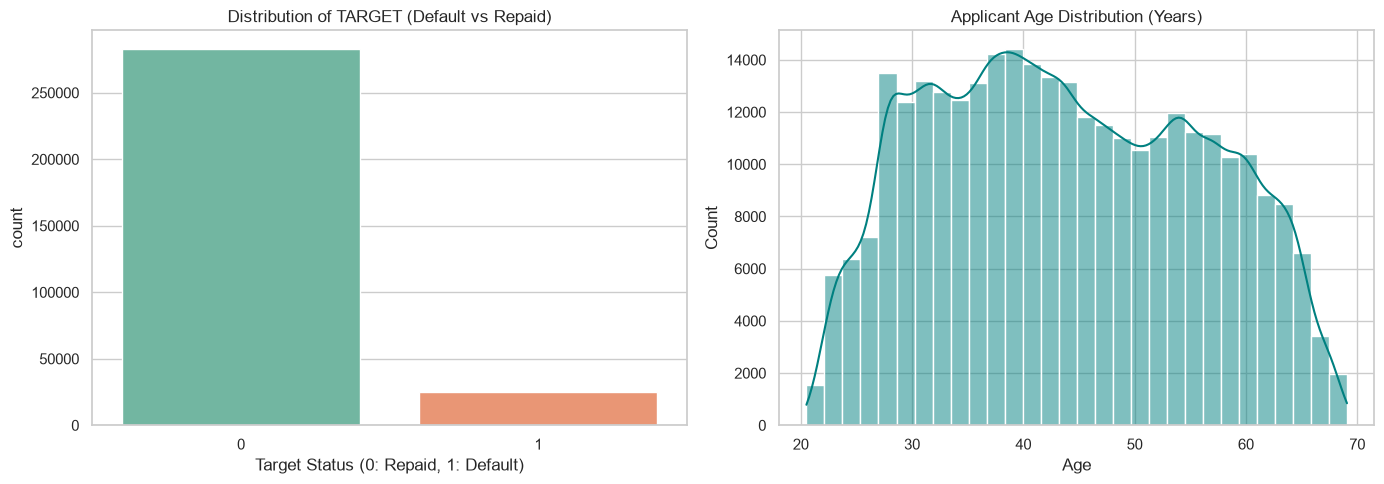

       AMT_INCOME_TOTAL    AMT_CREDIT    AMT_ANNUITY      AGE_YEARS
count      3.075110e+05  3.075110e+05  307499.000000  307511.000000
mean       1.687979e+05  5.990260e+05   27108.573909      43.906900
std        2.371231e+05  4.024908e+05   14493.737315      11.947950
min        2.565000e+04  4.500000e+04    1615.500000      20.503765
25%        1.125000e+05  2.700000e+05   16524.000000      33.984942
50%        1.471500e+05  5.135310e+05   24903.000000      43.121150
75%        2.025000e+05  8.086500e+05   34596.000000      53.886379
max        1.170000e+08  4.050000e+06  258025.500000      69.073238


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# Set visual style
sns.set_theme(style="whitegrid")

# 1. Do feature engineering lazily in Polars, then collect & convert to Pandas for Seaborn
df_pd = (
    df_train
    .with_columns(
        (pl.col("DAYS_BIRTH").abs() / 365.25).alias("AGE_YEARS")
    )
    .collect()
    .to_pandas()
)

# 2. Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Target Balance
sns.countplot(x='TARGET', hue='TARGET', data=df_pd, ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Distribution of TARGET (Default vs Repaid)')
axes[0].set_xlabel('Target Status (0: Repaid, 1: Default)')

# Plot 2: Age Distribution
sns.histplot(df_pd['AGE_YEARS'], bins=30, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Applicant Age Distribution (Years)')
axes[1].set_xlabel('Age')

plt.tight_layout()
plt.show()

# --- Statistical Summary for Key Numeric Features ---
key_metrics = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AGE_YEARS']
print(df_pd[key_metrics].describe())

In [7]:
import pandas as pd
from pathlib import Path
from IPython.display import display

DATA_DIR = Path("../home-credit-default-risk")

file_names = [
    "application_test",
    # "application_train",
    # "bureau",
    # "bureau_balance",
    # "credit_card_balance",
    # "installments_payments",
    # "POS_CASH_balance",
    # "previous_application"
]

# Read the first file as an example
df = pd.read_csv(DATA_DIR / f"{file_names[0]}.csv")

# Display selected dataset
display(df.head(5))
display(df.tail(5))

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
48739,456221,Cash loans,F,N,Y,0,121500.0,412560.0,17473.5,270000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
48740,456222,Cash loans,F,N,N,2,157500.0,622413.0,31909.5,495000.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
48741,456223,Cash loans,F,Y,Y,1,202500.0,315000.0,33205.5,315000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,3.0,1.0
48742,456224,Cash loans,M,N,N,0,225000.0,450000.0,25128.0,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,2.0
48743,456250,Cash loans,F,Y,N,0,135000.0,312768.0,24709.5,270000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0


In [4]:

import pandas as pd
from pathlib import Path
from IPython.display import display

# Dataset directory
DATA_DIR = Path("../home-credit-default-risk")

# Select dataset
file_name = "application_train"

# Features to inspect
features = [
    # External credit scores
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",

    # Financial information
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",

    # Demographics and employment
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "OCCUPATION_TYPE",
    "ORGANIZATION_TYPE",
    "NAME_CONTRACT_TYPE",

    # Credit bureau inquiry frequency
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_DAY",
    "AMT_REQ_CREDIT_BUREAU_WEEK",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR",

    # Social circle payment difficulties
    "DEF_30_CNT_SOCIAL_CIRCLE",
    "DEF_60_CNT_SOCIAL_CIRCLE",

    # Phone and regional information
    "DAYS_LAST_PHONE_CHANGE",
    "REGION_RATING_CLIENT",
    "REGION_RATING_CLIENT_W_CITY"
]

# Load selected features
df = pd.read_csv(
    DATA_DIR / f"{file_name}.csv",
    usecols=features
)

# Dataset overview
print("--- DATASET OVERVIEW ---")
print(f"Rows: {df.shape[0]:,}")
print(f"Features: {df.shape[1]}")

# Display first and last 5 rows
print("\n--- FIRST 5 ROWS ---")
display(df.head(5))

print("\n--- LAST 5 ROWS ---")
display(df.tail(5))

# # Display data types
# print("\n--- DATA TYPES ---")
# display(df.dtypes.to_frame(name="Data Type"))

--- DATASET OVERVIEW ---
Rows: 307,511
Features: 25

--- FIRST 5 ROWS ---


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,OCCUPATION_TYPE,...,EXT_SOURCE_3,DEF_30_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,Cash loans,202500.0,406597.5,24700.5,351000.0,Working,Secondary / secondary special,-9461,-637,Laborers,...,0.139376,2.0,2.0,-1134.0,0.0,0.0,0.0,0.0,0.0,1.0
1,Cash loans,270000.0,1293502.5,35698.5,1129500.0,State servant,Higher education,-16765,-1188,Core staff,...,NaN,0.0,0.0,-828.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Revolving loans,67500.0,135000.0,6750.0,135000.0,Working,Secondary / secondary special,-19046,-225,Laborers,...,0.729567,0.0,0.0,-815.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Cash loans,135000.0,312682.5,29686.5,297000.0,Working,Secondary / secondary special,-19005,-3039,Laborers,...,NaN,0.0,0.0,-617.0,NaN,NaN,NaN,NaN,NaN,NaN
4,Cash loans,121500.0,513000.0,21865.5,513000.0,Working,Secondary / secondary special,-19932,-3038,Core staff,...,NaN,0.0,0.0,-1106.0,0.0,0.0,0.0,0.0,0.0,0.0



--- LAST 5 ROWS ---


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,OCCUPATION_TYPE,...,EXT_SOURCE_3,DEF_30_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
307506,Cash loans,157500.0,254700.0,27558.0,225000.0,Working,Secondary / secondary special,-9327,-236,Sales staff,...,NaN,0.0,0.0,-273.0,NaN,NaN,NaN,NaN,NaN,NaN
307507,Cash loans,72000.0,269550.0,12001.5,225000.0,Pensioner,Secondary / secondary special,-20775,365243,NaN,...,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
307508,Cash loans,153000.0,677664.0,29979.0,585000.0,Working,Higher education,-14966,-7921,Managers,...,0.218859,0.0,0.0,-1909.0,1.0,0.0,0.0,1.0,0.0,1.0
307509,Cash loans,171000.0,370107.0,20205.0,319500.0,Commercial associate,Secondary / secondary special,-11961,-4786,Laborers,...,0.661024,0.0,0.0,-322.0,0.0,0.0,0.0,0.0,0.0,0.0
307510,Cash loans,157500.0,675000.0,49117.5,675000.0,Commercial associate,Higher education,-16856,-1262,Laborers,...,0.113922,0.0,0.0,-787.0,0.0,0.0,0.0,2.0,0.0,1.0


Loading application_train.csv...
Rows: 307,511 | Columns: 128
Baseline Default rate: 8.07%

Generating Target & Missing Values overview plots...


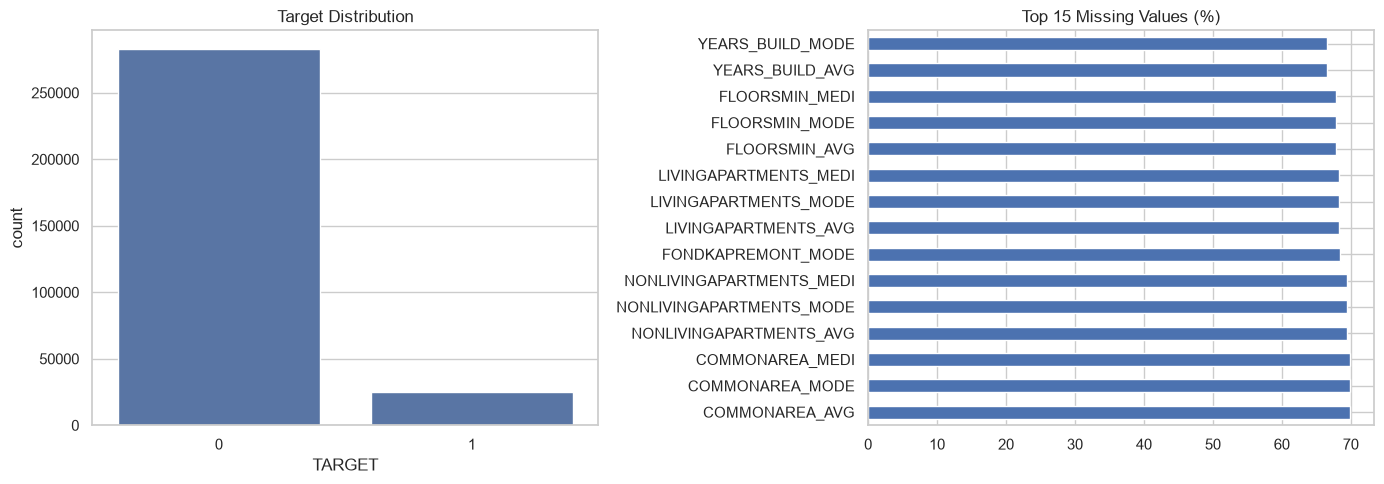

In [5]:
# ==================================================
# MODULE 1: Base Setup, Cleaning & Initial Overview
# ==================================================
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configure visual style for charts
sns.set_theme(style="whitegrid")
DATA_DIR = Path("../home-credit-default-risk")

print("Loading application_train.csv...")
app = pd.read_csv(DATA_DIR / "application_train.csv")

# 1. Clean anomalies: Replace Home Credit's placeholder value (365243 days) with NaN
app["DAYS_EMPLOYED"] = app["DAYS_EMPLOYED"].replace(365243, np.nan)

# 2. Engineer core base features (converting days to human-readable years and financial ratios)
features = pd.DataFrame({
    "AGE": -app["DAYS_BIRTH"] / 365,
    "YEARS_EMPLOYED": -app["DAYS_EMPLOYED"] / 365,
    "CREDIT_INCOME": app["AMT_CREDIT"] / app["AMT_INCOME_TOTAL"].replace(0, np.nan),
    "ANNUITY_INCOME": app["AMT_ANNUITY"] / app["AMT_INCOME_TOTAL"].replace(0, np.nan),
    "CREDIT_GOODS": app["AMT_CREDIT"] / app["AMT_GOODS_PRICE"].replace(0, np.nan),
    "CREDIT_TERM": app["AMT_CREDIT"] / app["AMT_ANNUITY"].replace(0, np.nan),
})

app = pd.concat([app, features], axis=1)

# Calculate baseline default rate percentage across the dataset
BASE = app["TARGET"].mean() * 100
print(f"Rows: {len(app):,} | Columns: {len(app.columns)}")
print(f"Baseline Default rate: {BASE:.2f}%\n")

# 3. Visualize Target Distribution and Top Missing Values
print("Generating Target & Missing Values overview plots...")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot target class balance (0 = repaid, 1 = default)
sns.countplot(data=app, x="TARGET", ax=ax[0])
ax[0].set_title("Target Distribution")

# Plot top 15 columns with the highest percentage of missing values
missing = app.isna().mean().mul(100).nlargest(15)
missing.plot.barh(ax=ax[1])
ax[1].set_title("Top 15 Missing Values (%)")

plt.tight_layout()
plt.show()

Generating numerical feature distributions and decile default rates...


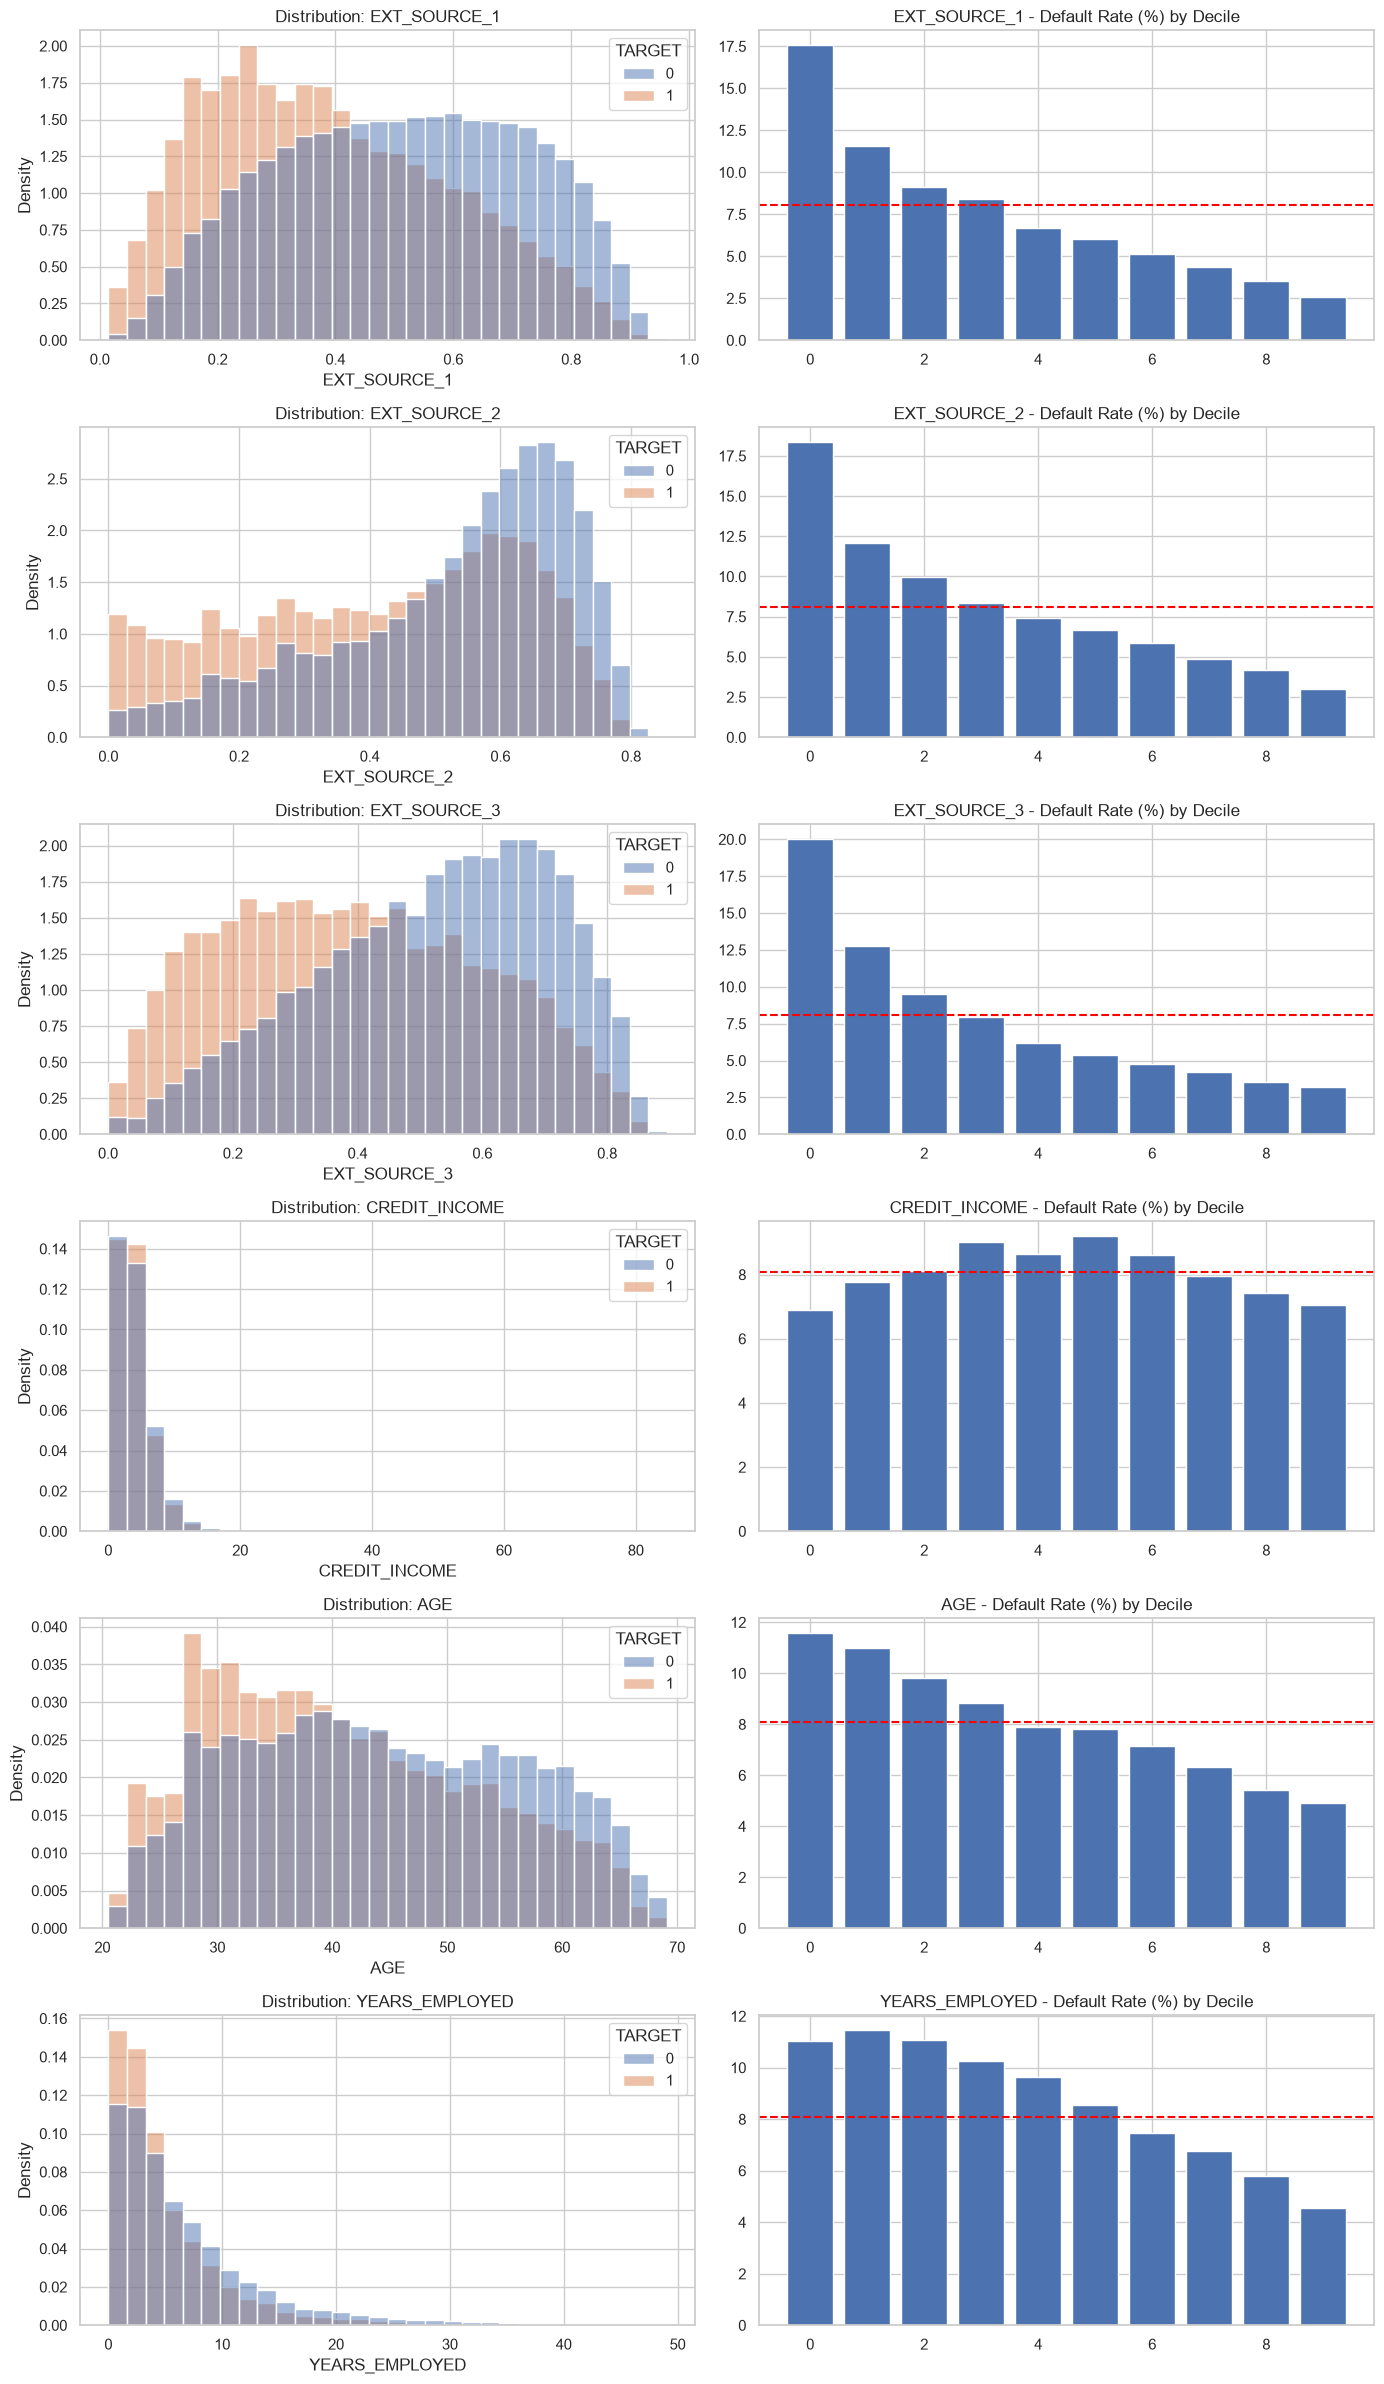

Generating categorical default rate charts...


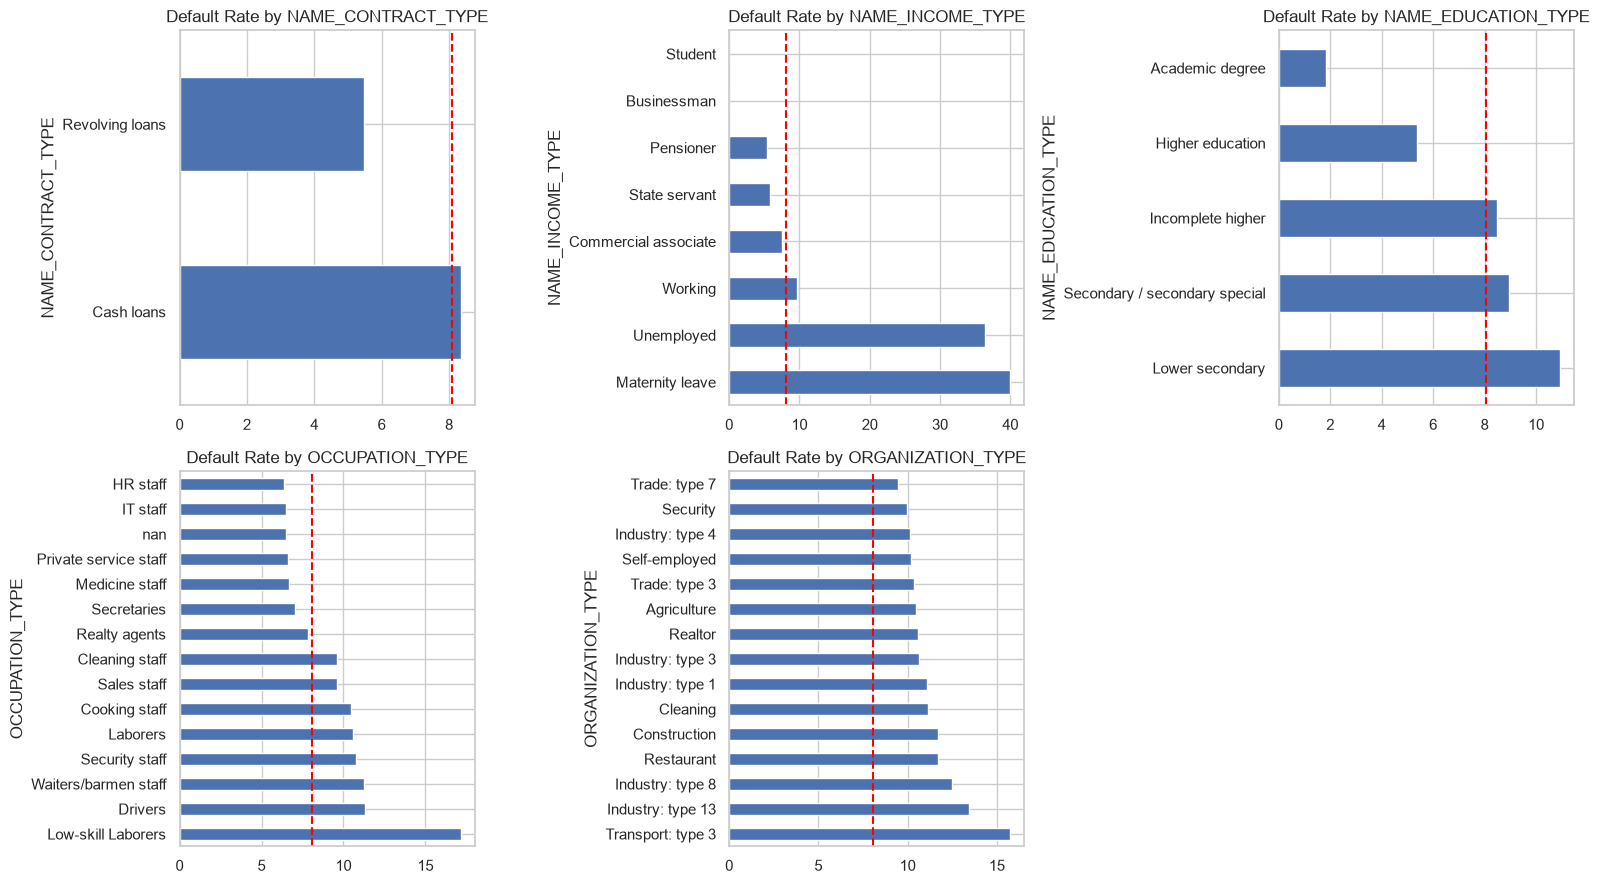

In [6]:
# ==================================================
# MODULE 2: Application Feature Exploration & Visualization
# ==================================================


def explore(df, cols):
  """Helper function to visualize numerical feature distributions (by target)

  and quantile-bucketed default rates compared to the global baseline.
  """
  fig, axes = plt.subplots(len(cols), 2, figsize=(14, 4 * len(cols)))
  axes = np.atleast_2d(axes)

  for i, col in enumerate(cols):
    # Left subplot: Histogram of the feature split by TARGET (0 vs 1)
    sns.histplot(
        data=df,
        x=col,
        hue="TARGET",
        bins=30,
        stat="density",
        common_norm=False,
        ax=axes[i, 0],
    )
    axes[i, 0].set_title(f"Distribution: {col}")

    # Right subplot: Default rate (%) across 10 quantile deciles vs global baseline
    s = df[[col, "TARGET"]].dropna()
    if s[col].nunique() > 1:
      bins = pd.qcut(s[col], 10, duplicates="drop")
      rates = s.groupby(bins, observed=True)["TARGET"].mean() * 100
      axes[i, 1].bar(range(len(rates)), rates)
      axes[i, 1].axhline(
          BASE, color="red", ls="--"
      )  # Red dashed line = global default rate
      axes[i, 1].set_title(f"{col} - Default Rate (%) by Decile")

  plt.tight_layout()
  plt.show()


print("Generating numerical feature distributions and decile default rates...")
# Explore key numerical features and ratios created in Module 1
explore(app, [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "CREDIT_INCOME",
    "AGE",
    "YEARS_EMPLOYED",
])

print("Generating categorical default rate charts...")
cat_features = [
    "NAME_CONTRACT_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "OCCUPATION_TYPE",
    "ORGANIZATION_TYPE",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for i, col in enumerate(cat_features):
  # Calculate default rate percentage for each category
  rates = app.groupby(col, dropna=False)["TARGET"].mean().mul(100)
  # Plot top categories by highest default rate
  rates.nlargest(15).plot.barh(ax=axes[i])
  axes[i].axvline(BASE, color="red", ls="--")  # Baseline reference line
  axes[i].set_title(f"Default Rate by {col}")

# Hide any unused subplots in the 2x3 grid
for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [7]:
# ==================================================
# MODULE 3: Credit Bureau & Bureau Balance Integration
# ==================================================
print("Processing Bureau data...")
bureau = pd.read_csv(DATA_DIR / "bureau.csv")

# 1. Flag active loans and aggregate bureau metrics at the client level (SK_ID_CURR)
bureau["ACTIVE"] = (bureau["CREDIT_ACTIVE"] == "Active").astype(int)

bureau_agg = bureau.groupby("SK_ID_CURR").agg(
    BUREAU_COUNT=("SK_ID_BUREAU", "count"),
    ACTIVE_COUNT=("ACTIVE", "sum"),
    MAX_OVERDUE=("CREDIT_DAY_OVERDUE", "max"),
    TOTAL_DEBT=("AMT_CREDIT_SUM_DEBT", "sum"),
)

print("Processing Bureau Balance data...")
bb = pd.read_csv(DATA_DIR / "bureau_balance.csv")

# 2. Flag days past due (DPD) statuses ('1' through '5') in monthly balances
bb["DPD"] = bb["STATUS"].isin(list("12345")).astype(int)

# 3. Aggregate DPD share at the individual loan level (SK_ID_BUREAU)
bb_agg = bb.groupby("SK_ID_BUREAU")["DPD"].mean().rename("DPD_SHARE")

# 4. Roll up loan-level DPD share to the client level via bureau mapping
bb_client = (
    bureau[["SK_ID_CURR", "SK_ID_BUREAU"]]
    .drop_duplicates()
    .merge(bb_agg, on="SK_ID_BUREAU")
    .groupby("SK_ID_CURR")["DPD_SHARE"]
    .mean()
)

# 5. Merge all bureau and bureau-balance features into the main application DataFrame
app = app.merge(bureau_agg, on="SK_ID_CURR", how="left")
app = app.merge(bb_client, on="SK_ID_CURR", how="left")

print(f"\nSuccess! Merged Bureau features. New shape: {app.shape}")
print(
    app[["SK_ID_CURR", "BUREAU_COUNT", "ACTIVE_COUNT", "DPD_SHARE"]].head()
    if "SK_ID_CURR" in app.columns
    else "Merged successfully."
)

Processing Bureau data...
Processing Bureau Balance data...

Success! Merged Bureau features. New shape: (307511, 133)
   SK_ID_CURR  BUREAU_COUNT  ACTIVE_COUNT  DPD_SHARE
0      100002           8.0           2.0   0.255682
1      100003           4.0           1.0        NaN
2      100004           2.0           0.0        NaN
3      100006           NaN           NaN        NaN
4      100007           1.0           0.0        NaN


In [10]:
# ==================================================
# MODULE 4: Secondary Tables & Repayment Behaviour
# ==================================================
print("Processing Previous Applications...")
prev = pd.read_csv(DATA_DIR / "previous_application.csv")

# 1. Flag refused and approved previous applications, then aggregate counts & rates
prev["REFUSED"] = (prev["NAME_CONTRACT_STATUS"] == "Refused").astype(int)
prev["APPROVED"] = (prev["NAME_CONTRACT_STATUS"] == "Approved").astype(int)

prev_agg = prev.groupby("SK_ID_CURR").agg(
    PREV_COUNT=("REFUSED", "size"),
    REFUSED_COUNT=("REFUSED", "sum"),
    REFUSED_RATE=("REFUSED", "mean"),
    APPROVED_COUNT=("APPROVED", "sum"),
)

print("Processing POS CASH, Credit Card, and Installments Payments...")

# 2. POS CASH Balance: Track max days past due (DPD) and late payment frequency
pos = pd.read_csv(DATA_DIR / "POS_CASH_balance.csv")
pos_agg = pos.groupby("SK_ID_CURR").agg(
    POS_MAX_DPD=("SK_DPD", "max"),
    POS_LATE_RATE=("SK_DPD", lambda x: (x > 0).mean()),
)

# 3. Credit Card Balance: Calculate credit utilization ratios and max DPD
cc = pd.read_csv(DATA_DIR / "credit_card_balance.csv")
cc["UTILIZATION"] = cc["AMT_BALANCE"] / cc["AMT_CREDIT_LIMIT_ACTUAL"].replace(
    0, np.nan
)

cc_agg = cc.groupby("SK_ID_CURR").agg(
    CC_UTILIZATION=("UTILIZATION", "mean"), CC_MAX_DPD=("SK_DPD", "max")
)

# 4. Installments Payments: Calculate lateness (days delayed) and underpaid ratios
inst = pd.read_csv(DATA_DIR / "installments_payments.csv")
inst["LATE"] = inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]
inst["UNDERPAID"] = (
    inst["AMT_INSTALMENT"] - inst["AMT_PAYMENT"]
).clip(lower=0) / inst["AMT_INSTALMENT"].replace(0, np.nan)

inst_agg = inst.groupby("SK_ID_CURR").agg(
    AVG_DAYS_LATE=("LATE", "mean"),
    LATE_RATE=("LATE", lambda x: (x > 0).mean()),
    UNDERPAID_RATE=("UNDERPAID", "mean"),
)


Processing Previous Applications...
Processing POS CASH, Credit Card, and Installments Payments...


In [13]:
def build_features(df):
    df = df.copy()
    df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)
    feats = pd.DataFrame({
        "AGE": -df["DAYS_BIRTH"] / 365,
        "YEARS_EMPLOYED": -df["DAYS_EMPLOYED"] / 365,
        "CREDIT_INCOME": df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"].replace(0, np.nan),
        "ANNUITY_INCOME": df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"].replace(0, np.nan),
        "CREDIT_GOODS": df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"].replace(0, np.nan),
        "CREDIT_TERM": df["AMT_CREDIT"] / df["AMT_ANNUITY"].replace(0, np.nan),
    })
    df = pd.concat([df, feats], axis=1)

    for extra in [bureau_agg, bb_client, prev_agg, pos_agg, cc_agg, inst_agg]:
        df = df.merge(extra, on="SK_ID_CURR", how="left")
    return df

app_train = build_features(pd.read_csv(DATA_DIR / "application_train.csv"))
app_test  = build_features(pd.read_csv(DATA_DIR / "application_test.csv"))

print(f"Train: {app_train.shape} | Test: {app_test.shape}")

OUT_DIR = DATA_DIR / "Processed"
OUT_DIR.mkdir(exist_ok=True)

app_train.to_parquet(OUT_DIR / "application_train_enriched.parquet", index=False)
app_test.to_parquet(OUT_DIR / "application_test_enriched.parquet", index=False)

print(f"Saved enriched train and test datasets to {OUT_DIR}")

Train: (307511, 144) | Test: (48744, 143)
Saved enriched train and test datasets to ..\home-credit-default-risk\Processed


In [18]:
# ==================================================
# MODULE 5: Split, Impute, Encode, Scale
# ==================================================
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

PROC = DATA_DIR / "Processed"
full  = pd.read_parquet(PROC / "application_train_enriched.parquet")
test  = pd.read_parquet(PROC / "application_test_enriched.parquet")

# 1. Stratified 80/20 split on the labelled data
y = full["TARGET"]
X = full.drop(columns=["TARGET", "SK_ID_CURR"])
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_test = test.drop(columns=["SK_ID_CURR"])

# 2. Preprocessing: median impute + scale numeric; mode impute + one-hot categorical
num_cols = X_tr.select_dtypes(include="number").columns.tolist()
cat_cols = X_tr.select_dtypes(exclude="number").columns.tolist()

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

# 3. Fit on TRAIN only, then transform train, validation and test
X_tr_c   = pre.fit_transform(X_tr)
X_val_c  = pre.transform(X_val)
X_test_c = pre.transform(X_test)

print(f"Train {X_tr_c.shape} | Valid {X_val_c.shape} | Test {X_test_c.shape}")
print(f"Default rate - train: {y_tr.mean():.4f} | valid: {y_val.mean():.4f}")

# 4. Save
X_tr_c.assign(TARGET=y_tr.values).to_parquet(PROC / "train_clean.parquet", index=False)
X_val_c.assign(TARGET=y_val.values).to_parquet(PROC / "validation_clean.parquet", index=False)
X_test_c.to_parquet(PROC / "test_clean.parquet", index=False)

Train (246008, 266) | Valid (61503, 266) | Test (48744, 266)
Default rate - train: 0.0807 | valid: 0.0807


Computing correlations with TARGET...


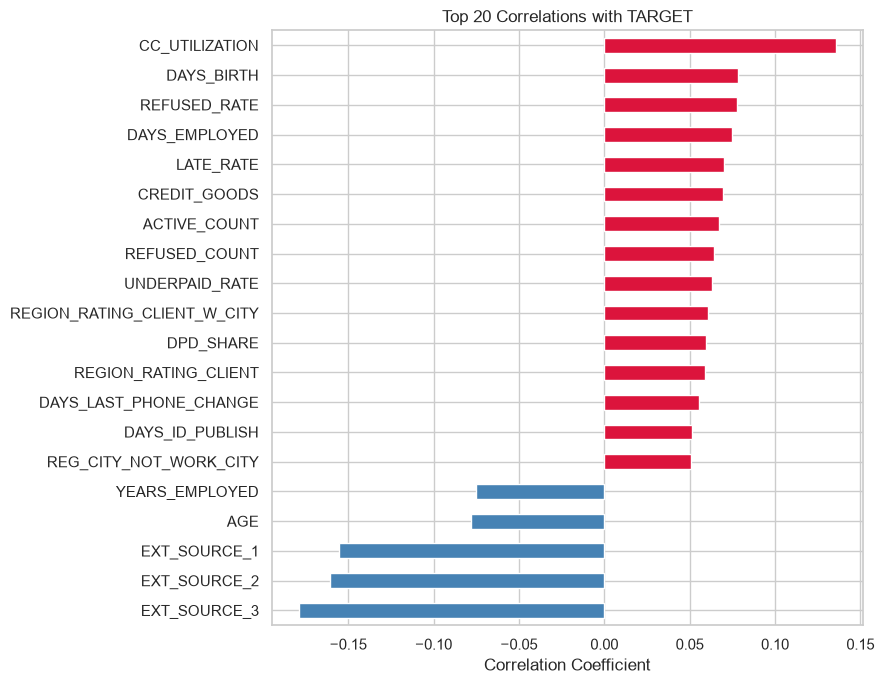


FINAL MERGED DATASET SUMMARY
Total Rows: 307,511
Total Columns: 144
Final Default Rate: 8.07%


In [ ]:
# OLD CODE

# ==================================================
# MODULE 5: Global Correlation & Final Summary
# ==================================================
print("Computing correlations with TARGET...")
corr = (
    app.select_dtypes(include="number")
    .corr()["TARGET"]
    .drop(["TARGET", "SK_ID_CURR"], errors="ignore")
    .dropna()
)

# Select top 20 absolute correlations (strongest positive & negative)
top = corr.reindex(corr.abs().nlargest(20).index).sort_values()

# Plot top 20 correlations
top.plot.barh(
    figsize=(9, 7),
    color=["crimson" if x > 0 else "steelblue" for x in top]
)
plt.title("Top 20 Correlations with TARGET")
plt.xlabel("Correlation Coefficient")
plt.tight_layout()
plt.show()

# Print final merged dataset overview
print("\nFINAL MERGED DATASET SUMMARY")
print(f"Total Rows: {app.shape[0]:,}")
print(f"Total Columns: {app.shape[1]:,}")
print(f"Final Default Rate: {BASE:.2f}%")

In [15]:
print("Current working directory:", Path.cwd())
print("Data folder exists:", DATA_DIR.exists())
print("Processed folder exists:", (DATA_DIR / "Processed").exists())
print("Files in Processed:", list((DATA_DIR / "Processed").glob("*")))

Current working directory: c:\Users\Main\Documents\GitHub\AML COMP 6831\COMP6831_MachineLearning_Midtern\notebooks
Data folder exists: True
Processed folder exists: True
Files in Processed: [WindowsPath('../home-credit-default-risk/Processed/aggregate_bureau.parquet'), WindowsPath('../home-credit-default-risk/Processed/application_test_clean.parquet'), WindowsPath('../home-credit-default-risk/Processed/application_test_enriched.parquet'), WindowsPath('../home-credit-default-risk/Processed/application_train_clean.parquet'), WindowsPath('../home-credit-default-risk/Processed/application_train_enriched.parquet')]


In [16]:
from pathlib import Path
import polars as pl

DATA_DIR = Path("../home-credit-default-risk")
bb_path = DATA_DIR / "bureau_balance.csv"

# 1. Scan lazily
df_bb_lazy = pl.scan_csv(bb_path)

# # 2. Extract the first SK_ID_BUREAU value from the file
# first_bureau_id = df_bb_lazy.select("SK_ID_BUREAU").first().collect().item()
# print(f"Inspecting all monthly records for SK_ID_BUREAU: {first_bureau_id}")

# 2. Set your specific SK_ID_BUREAU value
target_bureau_id = 5230570
print(f"Inspecting all monthly records for SK_ID_BUREAU: {target_bureau_id}")

# 3. Filter for all subrows belonging to that specific bureau loan
loan_history = df_bb_lazy.filter(pl.col("SK_ID_BUREAU") == first_bureau_id).collect()

# 4. Display the records
print(loan_history)

# Filter to show only the rows where STATUS is '5'
rows_with_5 = diverse_loan_history.filter(pl.col("STATUS") == "5")
print(rows_with_5)

Inspecting all monthly records for SK_ID_BUREAU: 5230570


NameError: name 'first_bureau_id' is not defined

In [22]:
# Filter for numeric delinquency statuses ('0' through '5') and sort to find the worst
worst_month = (
    diverse_loan_history
    .filter(pl.col("STATUS").is_in(["0", "1", "2", "3", "4", "5"]))
    .sort("STATUS", descending=True)
    .head(1)
)

print("Worst month for this loan:")
print(worst_month)

Worst month for this loan:
shape: (1, 3)
┌──────────────┬────────────────┬────────┐
│ SK_ID_BUREAU ┆ MONTHS_BALANCE ┆ STATUS │
│ ---          ┆ ---            ┆ ---    │
│ i64          ┆ i64            ┆ str    │
╞══════════════╪════════════════╪════════╡
│ 5230570      ┆ -66            ┆ 5      │
└──────────────┴────────────────┴────────┘


In [ ]:
# Multiple CPUs for Decison tree, now will submit the single one, here is code for multiple 

import pandas as pd
import numpy as np
from pathlib import Path
from itertools import product
from joblib import Parallel, delayed
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score
)

# ==========================================
# 1. Load & Preprocess Data (Skips if X_train_proc is already in memory)
# ==========================================
if 'X_train_proc' not in locals():
    # Uncomment and adjust if PROCESSED_DIR is not yet defined in your session:
    # PROCESSED_DIR = Path(".")
    
    X_train = pd.read_parquet(PROCESSED_DIR / 'X_train.parquet')
    X_valid = pd.read_parquet(PROCESSED_DIR / 'X_valid.parquet')

    y_train = pd.read_parquet(PROCESSED_DIR / 'y_train.parquet')['TARGET'].values.ravel()
    y_valid = pd.read_parquet(PROCESSED_DIR / 'y_valid.parquet')['TARGET'].values.ravel()

    # Drop unique identifier column if present
    if 'SK_ID_CURR' in X_train.columns:
        X_train = X_train.drop(columns=['SK_ID_CURR'])
        X_valid = X_valid.drop(columns=['SK_ID_CURR'])

    # Clean known Home Credit anomaly in DAYS_EMPLOYED (365243 -> NaN)
    if 'DAYS_EMPLOYED' in X_train.columns:
        X_train['DAYS_EMPLOYED'] = X_train['DAYS_EMPLOYED'].replace(365243, np.nan)
        X_valid['DAYS_EMPLOYED'] = X_valid['DAYS_EMPLOYED'].replace(365243, np.nan)

    cat_cols = X_train.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
    num_cols = X_train.select_dtypes(include=['number', 'bool']).columns.tolist()

    num_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    cat_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

    print("Preprocessing training and validation sets...")
    X_train_proc = preprocessor.fit_transform(X_train)
    X_valid_proc = preprocessor.transform(X_valid)

# ==========================================
# 2. Multi-Core Hyperparameter Tuning on Validation Set
# ==========================================
param_grid = {
    'max_depth': [5, 8, 12, 16],
    'min_samples_split': [20, 100, 500],
    'criterion': ['gini', 'entropy']
}

combos = list(product(
    param_grid['max_depth'],
    param_grid['min_samples_split'],
    param_grid['criterion']
))

def train_and_evaluate_tree(depth, min_split, crit):
    # Strictly uses sklearn.tree.DecisionTreeClassifier
    dt = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_split=min_split,
        criterion=crit,
        random_state=42
    )
    dt.fit(X_train_proc, y_train)
    
    # Validation predictions
    y_val_pred = dt.predict(X_valid_proc)
    y_val_prob = dt.predict_proba(X_valid_proc)[:, 1]
    
    metrics = {
        'max_depth': depth,
        'min_samples_split': min_split,
        'criterion': crit,
        'Val Accuracy': accuracy_score(y_valid, y_val_pred),
        'Val Precision': precision_score(y_valid, y_val_pred, zero_division=0),
        'Val Recall': recall_score(y_valid, y_val_pred, zero_division=0),
        'Val F1-Score': f1_score(y_valid, y_val_pred, zero_division=0),
        'Val ROC-AUC': roc_auc_score(y_valid, y_val_prob)
    }
    return (depth, min_split, crit), dt, metrics

print(f"\nTuning {len(combos)} DecisionTreeClassifier models across all CPU cores (n_jobs=-1)...")
parallel_out = Parallel(n_jobs=-1, verbose=5)(
    delayed(train_and_evaluate_tree)(d, s, c) for d, s, c in combos
)

dt_models = {k: model for k, model, _ in parallel_out}
tuning_results = [m for _, _, m in parallel_out]

results_df = pd.DataFrame(tuning_results)
results_df = results_df.sort_values(by='Val ROC-AUC', ascending=False).reset_index(drop=True)

print("\n=== Intermediate Validation Results (Sorted by Val ROC-AUC) ===")
print(results_df.to_string(index=False, float_format="%.4f"))

# Select best configuration based on Validation ROC-AUC
best_row = results_df.iloc[0]
best_config = (
    int(best_row['max_depth']),
    int(best_row['min_samples_split']),
    best_row['criterion']
)
best_dt_model = dt_models[best_config]

print(
    f"\nBest Configuration: max_depth={best_config[0]}, "
    f"min_samples_split={best_config[1]}, criterion='{best_config[2]}' "
    f"(Val ROC-AUC = {best_row['Val ROC-AUC']:.4f})"
)

# ==========================================
# 3. Final Evaluation (Train vs. Validation)
# ==========================================
def evaluate_dt_split(model, X, y, split_name):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    
    cm = confusion_matrix(y, y_pred)
    metrics = {
        'Split': split_name,
        'Accuracy': accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred, zero_division=0),
        'Recall': recall_score(y, y_pred, zero_division=0),
        'F1-Score': f1_score(y, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y, y_prob)
    }
    return metrics, cm

train_metrics, train_cm = evaluate_dt_split(best_dt_model, X_train_proc, y_train, 'Training')
valid_metrics, valid_cm = evaluate_dt_split(best_dt_model, X_valid_proc, y_valid, 'Validation')

summary_df = pd.DataFrame([train_metrics, valid_metrics])
print("\n=== Best Decision Tree Training & Validation Metrics ===")
print(summary_df.to_string(index=False, float_format="%.4f"))

print(f"\n=== Training Confusion Matrix {best_config} ===")
print(pd.DataFrame(train_cm, index=['Actual 0', 'Actual 1'], columns=['Pred 0', 'Pred 1']))

print(f"\n=== Validation Confusion Matrix {best_config} ===")
print(pd.DataFrame(valid_cm, index=['Actual 0', 'Actual 1'], columns=['Pred 0', 'Pred 1']))